# LIFESTYLE DATA EXAMPLE

This is a rough sketch on how to use Undersampling / ClusterCentroids.

# Undersampling with ClusterCentroids

With ClusterCentroids, the dataset has to be in all numeric format (categories etc.), in similar manner as in machine learning applications.

In [8]:
# pip install imblearn
import pandas as pd
import numpy as np
import seaborn as sns
from imblearn.under_sampling import RandomUnderSampler, ClusterCentroids

---

In [9]:
df = pd.read_csv("../../lifestyle_sustainability_data_processed.csv")

# need to drop NaNs first
df = df.dropna()

<Axes: xlabel='Rating', ylabel='Count'>

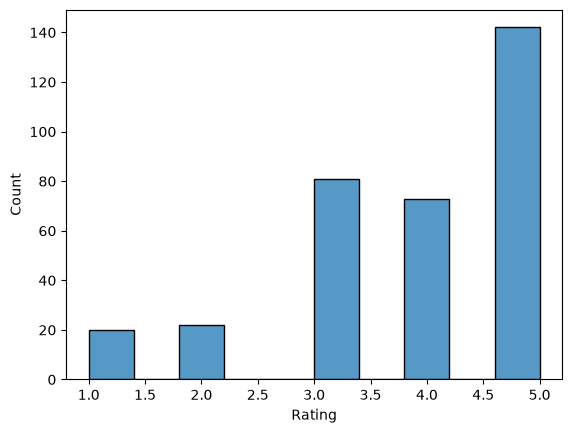

In [10]:
# Show the distribution
sns.histplot(df, x="Rating")

In [11]:
# Another x y split to prevent a data leakage
X = df.drop(columns="Rating", axis=1)
y = df['Rating']

# Here, we tell the sampler what distribution we would like to have.
# Often times, this isn't necessary -- But sometimes it gets rid of far
# too much data if you don't.
strategy = {
    1: 20,
    2: 20,
    3: 30,
    4: 30,
    5: 35
}

# use ClusterCentroids to undersample
# but also using a sampling strategy (to enforce a certain distribution)
sampler = ClusterCentroids(sampling_strategy=strategy, random_state=321)

# perform undersampling
X_resampled, y_resampled = sampler.fit_resample(X, y)

# reconstruct the dataframe
df_resampled = pd.DataFrame(X_resampled)
df_resampled["Rating"] = y_resampled


c:\Users\tuomas.valtanen\dataeng_advda2026_lectures\DataEngineering_AdvDA_2026\.venv\Lib\site-packages\sklearn\base.py:1403: ConvergenceWarning: Number of distinct clusters (16) found smaller than n_clusters (20). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


<Axes: xlabel='Rating', ylabel='Count'>

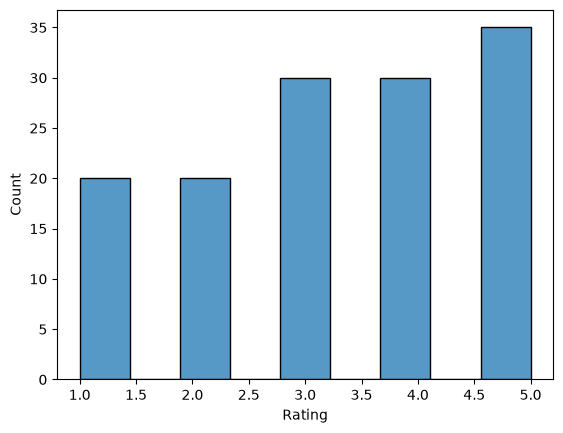

In [12]:
sns.histplot(df_resampled, x="Rating")

In [13]:
df.describe()

,Age,LocalFoodFrequency,HomeSize,ClothingFrequency,SustainableBrands,EnvironmentalAwareness,CommunityInvolvement,MonthlyElectricityConsumption,MonthlyWaterConsumption,UsingPlasticProducts,...,EnergySource_Mixed,EnergySource_Non-Renewable,HomeType_Apartment,HomeType_House,Gender_Female,Gender_Male,Gender_Non-Binary,DisposalMethods_Combination,DisposalMethods_Composting,DisposalMethods_Landfill
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,...,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,43.872781,1.597633,1505.849112,1.236686,0.650888,3.381657,1.035503,265.343195,2947.408284,1.369822,...,0.369822,0.165680,0.301775,0.485207,0.434911,0.307692,0.130178,0.195266,0.263314,0.174556
std,14.491943,0.939218,648.900726,0.960751,0.477396,1.234718,0.796085,116.588528,1084.719392,1.011466,...,0.483472,0.372345,0.459709,0.500522,0.496480,0.462223,0.336998,0.396993,0.441084,0.380150
min,18.000000,0.000000,407.000000,0.000000,0.000000,1.000000,0.000000,55.000000,538.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,31.250000,1.000000,975.000000,0.000000,0.000000,3.000000,0.000000,159.250000,2000.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,44.000000,2.000000,1450.000000,1.000000,1.000000,3.000000,1.000000,270.000000,3100.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,56.000000,2.000000,1919.250000,2.000000,1.000000,4.000000,2.000000,355.000000,3843.750000,2.000000,...,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
max,96.000000,3.000000,2997.000000,3.000000,1.000000,5.000000,2.000000,498.000000,4979.000000,3.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [14]:
df_resampled.describe()

,Age,LocalFoodFrequency,HomeSize,ClothingFrequency,SustainableBrands,EnvironmentalAwareness,CommunityInvolvement,MonthlyElectricityConsumption,MonthlyWaterConsumption,UsingPlasticProducts,...,EnergySource_Non-Renewable,HomeType_Apartment,HomeType_House,Gender_Female,Gender_Male,Gender_Non-Binary,DisposalMethods_Combination,DisposalMethods_Composting,DisposalMethods_Landfill,Rating
count,135.000000,135.000000,135.000000,135.000000,135.000000,135.000000,135.000000,135.000000,135.000000,135.000000,...,135.000000,135.000000,135.000000,135.000000,135.000000,135.000000,135.000000,135.000000,135.000000,135.000000
mean,46.207407,1.251852,1631.311111,1.251852,0.288889,2.829630,0.948081,313.348148,3232.237037,1.540741,...,0.266667,0.311111,0.303704,0.207407,0.244444,0.111111,0.125926,0.118519,0.274074,3.296296
std,15.614811,0.928154,741.811674,0.911932,0.454934,1.249124,0.734940,118.278593,1215.223511,1.097915,...,0.443864,0.464672,0.461569,0.406960,0.431358,0.315440,0.333001,0.324425,0.447708,1.387976
min,18.000000,0.000000,407.000000,0.000000,0.000000,1.000000,0.000000,80.000000,538.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,33.500000,1.000000,987.000000,1.000000,0.000000,2.000000,0.000000,208.500000,2141.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
50%,46.000000,1.000000,1617.000000,1.000000,0.000000,3.000000,1.000000,325.000000,3470.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
75%,59.000000,2.000000,2215.000000,2.000000,1.000000,4.000000,1.500000,400.000000,4241.000000,3.000000,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,5.000000
max,96.000000,3.000000,2988.000000,3.000000,1.000000,5.000000,2.000000,498.000000,4979.000000,3.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,5.000000


In [15]:
# switching to decimal notation for the variance checks
pd.set_option('display.float_format', lambda x: "%.2f" % x)

In [16]:
df.var(numeric_only=True)

Age                                     210.02
LocalFoodFrequency                        0.88
HomeSize                             421072.15
ClothingFrequency                         0.92
SustainableBrands                         0.23
EnvironmentalAwareness                    1.52
CommunityInvolvement                      0.63
MonthlyElectricityConsumption         13592.88
MonthlyWaterConsumption             1176616.16
UsingPlasticProducts                      1.02
PhysicalActivities                        0.62
Rating                                    1.44
Location_Rural                            0.20
Location_Suburban                         0.23
Location_Urban                            0.23
DietType_Balanced                         0.23
DietType_Mostly Animal-Based              0.13
TransportationMode_Bike                   0.20
TransportationMode_Car                    0.13
TransportationMode_Public Transit         0.21
EnergySource_Mixed                        0.23
EnergySource_

In [17]:
df_resampled.var(numeric_only=True)

Age                                     243.82
LocalFoodFrequency                        0.86
HomeSize                             550284.56
ClothingFrequency                         0.83
SustainableBrands                         0.21
EnvironmentalAwareness                    1.56
CommunityInvolvement                      0.54
MonthlyElectricityConsumption         13989.83
MonthlyWaterConsumption             1476768.18
UsingPlasticProducts                      1.21
PhysicalActivities                        0.60
Location_Rural                            0.18
Location_Suburban                         0.20
Location_Urban                            0.17
DietType_Balanced                         0.22
DietType_Mostly Animal-Based              0.18
TransportationMode_Bike                   0.13
TransportationMode_Car                    0.19
TransportationMode_Public Transit         0.16
EnergySource_Mixed                        0.20
EnergySource_Non-Renewable                0.20
HomeType_Apar